# LAB 07 — Danh_Gia_Mo_Hinh

**Notebook Google Colab | Học máy ứng dụng | Lab 07**

Nội dung theo tài liệu `Lab07_DanhGiaMoHinh(1).pdf`: **phần thực hành theo từng bước + giải 6 bài tập cuối bài**. Các lệnh có chú thích và in kết quả để tiện chụp màn hình.

**Cách sử dụng:** mở tệp `.ipynb` bằng Google Colab → **Runtime → Run all**. Chạy lần lượt từ đầu; dữ liệu CSV được khôi phục tự động trong bước chuẩn bị, không phải tải CSV bằng tay. Ảnh và bảng kết quả được xuất ra thư mục `ket_qua/`. Những kết quả mô hình hoặc thời gian chạy có thể thay đổi theo phiên bản thư viện hoặc máy.

## Chuẩn bị — thư viện, dữ liệu và thư mục kết quả

Bộ dữ liệu lấy trực tiếp từ ZIP người dùng cung cấp, được nhúng vào notebook để mở bằng Colab là chạy được.

In [1]:
# Chuẩn bị dữ liệu gốc đính kèm (tự giải nén, không cần upload riêng).
import base64, io, os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_DATA_BASE64 = "UEsDBBQAAAAIAKhRNl3neLqEtQEAAM0DAAAQAAAAZGF0YS9naWFfbmhhLmNzdkWTTW5CMQyE90jcJIriOLGd0yDUVoUNVGp7/844QJffG/+M7bz368ft9HN9u5Tv++nrcr99lp/f+/V0u5zL5/V8POiss0iRKFob0KuVXhwUfjyMVQewtzJqn8kNLAa2xMXkjvC1jofZEA5eDB9gqcJw3+FTE3uZtQVwIhsAcVE1OHkEB+VIWRrCh704KMOKteqUB2ShvOBcSiJam1RlL1afkO1Rnbp2sGY4B1vxL9Nb78lWlJOgnCaznEzqWIzNGtQVbIh32WaNjPbecq2tWBXKClSWRx1J+TWbU+97MyynM+Pt2W7GiwfTk7Dx0ml2kUeyF68Cb27YjHJ0DBHJPNoC8qa+cjRk7/BozxtjppF6jhqInyn7ngzVcOPouamG7I7iMZAN2yWqYLCI7JXFsfXA+HuNXlVTlr1m5yDhucXeHk5TVj4BWH1hZy+Fs8WbDi4deUhfuidhr42cWxjuSF9WuTJamzC+PJ2mNZ588T0pd+7ZXFpPNxnfybrb483VNvhhZMEAL3/yTlAi38zAGfDTAEW2nQE23x/yhGDPgH1GQzrtivh+JIEAWfzAH2RwIPx2WO4fUEsDBBQAAAAIAA4AX13jk0lKiBIAABhAAAAZAAAAZGF0YS9zaW5oX3ZpZW5fYm9faG9jLmNzdl1b267kxg18D5A/EQ7U99bXLOLEsBeIvQ9x8v2ZZrGK1OK8rHZmpG42WSwWqX99//WPb3/9cv3nx7df/vvj+7f//ePP366/vv/57Z+/f//254/rt+8/vv37H5+v/P7rH9cvP779/uOff//b/rqvdt3n71w817jKtc5F+2qfT8rVz8X86vY1+2R9vtY+X6wNP+pX/VxX/6xf56tl47PP7e7Px7Xjw/Owdj24aNe2+9j99zU/D7OL8VXPU7Gm8bnFOHfAb8rna7c/eXx+dJZbBp7VPsubV6u8Gp/7l8KNlc8tHjxrnrtdRcs/26z+tPPghn2eR/ezrIqfrc9/12tzJ9Ue8LnotsSC9fbPHcr521zwud6832dFlz/3/L77VvC9zy4L724PvvHg5/Pgjtsv7vnmsRzDfRZfcJbHOsWt+JjZ3L4trDg+Oxlni+dH58A+N/vcc4Zx1lU6V/w5WTfVY+fixplfZ1cf09R9bjPNC+7Xdu5k/XOfzSWbhdwjjummXx0THy/7LKUcSy7zluI2mZ9vfrZU6YL97Ghxd/BP34E9YOI44FbwinMFr/YdnGVxJWddm/c4Fhny6duM94Tz33SlBTtWevTb988Sacnbnju5lwcrPmsqcEff5nlO8atz9MdjHh5o+MgJkpkcYSBUubFz1GVwjSNcsNPCvuCzqOLu7lf4VUWkyVTHBfHFbX5QfWfd7n9rIfnZm34wwu8Gg+u2Y1pwQvNAYo3ByVUH1rjM+KVw/edrnaDRLYjck85n7eYpnYDcgSfm0wXnMghlw72xylnM4S0yYKuh8AdCyTp20o1ntohXyz7y7519bXnEcdPCJz+GIMSJ5ofkFrXHnp8WHju/OCzGh36GI6v44kSwurfMQJ721RFmG9Y+OMkvbh67YOkgVKl0uZa8ceNs/TM/201PbXLHc9IGNgSD43M1LHfLco8tWSddlSu2OeAkqOJw/aICAhs2U2DHFSlhyr/xZD7sRrxPbqYI9pZtrXAhDYZcPNDJZ8MnlvvmNgdU1G38ypePeOft7wT223Ai/awrIhHw3VEOa9SjVwLO4ZZ7iKktuVlP+0RUb7fW87XMARXw5mcLCF4j+T+2ma6HLXOKehO9jg1KALgQtSFrwbO6+Zn5REFwneNUmklwWDLt2DgzWeeWdYbBra0LR5ZA36Oz0PeP8w1i+WOkoxAMCdiblrJfldsgab2cZyTfL/Lv5aRkvrLW5kd3BoPwguknuAIMq04ax6nkdlJdETVqDITtJ1H0xapTmoZetNzjxK6HEwTlMT8FNDxufD7MgP3SDRV124zjeW/bJyOlEYtP2e381bSX5bdXsHbisuGJUlhXjMCo7t/dj3pFdN5XooACmgXa1PmjyKvDvM9PrH8WNYP0dsKJrqYcZIHVpKtGkHgyxCE1t0a0Ss5dbVuRHrvY5vStTFrjASQhSQUrXQb6JW1skUYuhj4PzIz/EKuq+bdyTxNzRrrBDZF8+qWgXeefiLFmNtPhNeEKGPAiYy/mNHzwtt9sHqQRSsFFUUCQXt7cf4TwYQ4PfQ/OMAl2BYSg8VzNvzxlwwMmj6trUTiim9YAiSAvAfsoxHTjH5WOPl/JMbB6+aqKZ6VCnlLgYdXuI49t4lJgVjlvypvBaif3MuHNfhIWjVq/IcuKOCXqnjs+2jYSyq2shJy96OqNa0SIlebce2aqPxySH6L/QZmqEDZg4UfdAMlPusoXlVJvwpET5cIoCJ+oRnlFHbriD4hfWHQd4zRypBGJ8l2KwKaPTnAgDPjFIhb3KrMETfICcxelgkFuuVhMrlcqKExly9h7ISh0lSXwj6AY1VzEF1wSaangaoNB1+X7TBrvwnDnNfJpoLy10LHOSmry96CX1T4TMnalx03+MQN4izZwJ5LenQlVFTuifwjXj9EVJS1OI/nmtOwlZHCdgJuuCU9Pwt4vflBURSM34AwfC6dHZ7gMG+uiRYoSx3Bf3cTXEVQCOTpFHc+iO4Y03K/ksq1c9V2+V+F/DQrTvDSrTmvxmyo0PIcWSkejAzYnmk5vNkKpRz5UHuov10HKdugCHyjiS5YRG5d4AKmqwl1J3OiWHVTcLKTvQmwsUX+NOEzwnjawYEDX5t1FMVAF7hBLSiBQgTczyUUmm3bIIyXAkWqZluSEk+ZOzjhOWpj2deaoc6rUnSms3Zb2akKkW/E+mSA7d3PLVo8Bz+AOEMbajkywzVmUVVvmi1CcqkfOBgfvsOIwP6o6dtGP4ZUTzrZ7eVQHQ2lC9MDii6IFbr/ETmGCGfC65cKQlWrSQxqXDy5Z6QNd6WBn9zDePRJEFwd2N/6tBDDzzrbLBMoGx8B104VnxpWZqlZQjpoKhZJqtioPwWmGZ/WrU7vYPykxE5Zz/lSBvF5qQ99ySo44qz3QeyehcChPu1pUPEqw6FtVJ1heJxYYyM04tnqJhqUYhBWEcFoVuJsKlgGhZ2S0liZm1nn4xeAcyxykpmMq4d4Qi0ZgZpGpoHx1OpJ2NRni43UV+B8c95CdGh6R4BklNo9vJ5K/hJk3i+cgKj0qu+V5v8q4TaGEnDGc70EXKLe8bCfdC7ueikFIveXh0fYo08q7QOypjO8vKQMupyJziIIcSNpBYxq2reSbq1GUL0VkOTnVRoaVHz3a9/oCROPqsfxbxLUA9GUFr2sEtvYSWw1cJLq3pKZtc7ow+mMIlThllUnuLCg4cW6Ac+xbFVgTY4Dpgn5X8x8awVO61IymKypEVR5UmbmHx7WTpoEkcAdqZ6TIkII0oxL3kUUAIhQigbjSeu5cx+Doe+yzie+YOS4BohM7aDuDUDBJRCeDsDGCmjdbWNEkMWBSk1RFfoxE/uq5PiJNUAD4ZuUGmr+wYRyys/mW2XxNYuUkY+w8y8kKd7iHqQnQrDWiW0QfB4ecVI32EraT3J4bQ5uufVPfHHJEfbPA1kdkq5NOFL4Nbs/iUsVTwvzgEjOpqw9lK+kt5Zbus7yOCype7uTgLbncQ1YZiVG7xfdUEAflobBZlTs8dAsp1pC3A8okUwTW09lr4XHDLQo8tfPRzQOmVLaALK2LLA4pBIucODVzBOkojCLOZgJjOGHq2FSqJ6mcAq8pKjrQ4yx04ynnn18oWgjMbm4JRsn7S8Lz7WqHqp2ucF+80h0jc02vZlOrocp5e9ZDayrPJPckHbyS+/tHkmUzS6tGwKs80k701esSedmEje2ap6Ah2/6B+mPrqF5NDXY5ivCPqjKf3K8dYoTjtwh4S5WbslEhgetcCPJBxOH8qVgucfAqmqAMZSnBdBdJeUbKkonF4uHEwtQ7od5CHmxhfYrz0z2k3gFGakgWi7qizVSEhRxLPG+Did1E0iSm1EQG0GS6XTjDcQ4t8sZNCLK5cET6UVh0NdnZkw0loWuN05B6xmZmUo+RO1M/WGwR4wjRDKk6+OmjBCQlDQtZdP4nYmsZrYkuXvTIunGlcW5SfiLC8IlNZEC8FJ5LUV3T0D5v7KGknsT2JYoTR190sQ+dhPvwRhyuNMahlsTRS26VMke2tbRbFhWDiQLxZiW2okORDg0EWnQ3OA5VF9GJmtDWI8HjAicm6tVfCDWvElxgUj1hs48e4bdvYZAiKAM/iSCp1y2d9XkJT5CWaEiH8zs20Fgb7JfWdyJVMOqqkRJ2keAx/EDjjraDtNPmpe9WP1vWyjqMLfMOQB/SId5lSonkJAxvRDqXxEMrf2t9r7KViRYknyv2ilyjOjocNSYGHzYT38AtUy9CYs4Dclbi9lWJC9mpvjKLqM5KYnYPPopUEqVusQOMUYBQn8ASVQO52uwl1mBZXwISNdNTJF9vF7PTBEGPbcYJopRuSuvvnUG/j12rl0l2mRy+q94HMlenv66fdo7kRAkBrmQaPsxTkiuB1ksx1JzH4+0uCtEe5TviokorKRYYUrPHTzE/uXxUlZR90EtnlLiaKqJT5dLdRciWgqQyVwEqeLo+EEWACankZdTpqYoPQ7WYT2ao5/eg8UQ+4OKoYFCNl/1TW+pOnBlh0vSzCbpbuMwiIj6Z8gQdg7R2uwjM/NoT9m3aUlxwpRN28TmwoiSxOw0iPVfu18OT8wjUYoaCPlcUUSUVpCuqRGKFgO/JdcOKBLIv5DLf5bhkmzvVT9u2VXKWv2XgO8m0nOMpPJfNMu6xMZstcpql7uksWX2LqqTA2ZG6OTWwlYTQvWkKDLiEbDioLrAdW5KW8bJ8YRkL1qBYDV1muGpXO8/E3Vb9h/tSrVelrLGLTQBH0mToYq6uKL2uLEnIOYaPJKoDEUUDECTg9hjjkZeWFEzzPYe5Q19hXFX9yqdPCnNTvzwZJUJO6TUOYjK7LTdHUUYwcFFA7CheZqreh7OcGC2qFGwfmlszdlmH6EhGJbLKkNcibAddeCrHIIc1546oMbeGT3tC6f3WwZ9U80/DligeK/KbxLQ8PePdJW3Vyh4x0qzkATDinvst9T7qIaiVUVLHU8Ve5NPlnOvlTdF7DgzvrEgt1tD/lEDn3kPjoXdU6DHDb9icMrKP5GqaRiUTj80WQXt1hJHtQJMs3BU0IOJa/U6EcRpCkR5lIoWblHH1/DQwb87MaVkztLCSlCH43bgSqUrqJbpRaqTXVKltGvVms+6mHT3ieUqScJe30aOmyEqT1/yDn1nCKfSeqgE6dv7r/fpdiw007sZlLrWBDhGRLjElv06OdyXNLs+hdGk/SCZLftZsLKWHQnL/TDTTcJ2W9YTetVw7FLdp4Uo+HiVMNCklTVWmSbWoQZm4Y0DZxMg01lcjl6QzG5bGNk1qhKKHAJB5mhknTVDcqT+3X1hnx6SWaFJqW1xI7pIcW7In1YSCC5xnEgVtzKUpQz+R/2vIJRQbtYxC/jN9DPsOA9+C/hY8iTOgsmFNnukezUSYB68RSwpwQycCpw+YcuAAaUyDtTWN2akRs7yYu7NHET8AEtEen/J71EY9tKOSeGOPoS0K3PFigbgLziEG4vOQ8EPvS7TRU/zD+UeJrcDUm+W5eoLQdcg1waofAoul7pJ5YpLCXWfv9qiJSOwcZgrHy0pR/RkVWfQ6HAmc+qWW2w3zpvbSStMvLWmEO0kXSP5DWpHXMTc33cPAIwJzvea4Mb4aQDJ82DStX4xkXi+JME82TdVWy5ZfL/H1pBBWaEZq0h96nUfSffr7IYn0VNBtRTP8N7SJxIDXa7B1+D0WTRrNyMlSZzG/Vpi7kNqXpA1JE/QYiy7pe+pQvdXxkm6mZ00Aq6p5Zw7Py7dH1pBN2g+iAhKgd3mmDpA2SDMjNWkw/aoa68slKgUsVpSuPTfkJHTinI08Rl+bpiKiaNxE8sHEKZ+WkVuEe03DGl1wQpWtB6pLC/VOiARmxb7NT+jlj7Pt++0Hk6TFH9z03s/VLolXM0EhZp6SislQatHUUd2SeGHwJaYaoY4LbvhevLiyObqyuMROyXQ504lkaxCqtlZ+FaEn2jmpdqTmXLzTMfEKlrfqnihIRHlvGRX/4SlgJvHjsWJFJpa9vXEeJzGUbRkyKn7sfhtM57nSNDkaf0kB7yrPevJhNlPEekxQSnxGk78AbyabDjMKX1+Tv+ojTB8efmFmVKvRJe+2jBnqWpJcMflcZxy0e/Pw1wtUDETBMs2Zl5RgAIiYalEibqTFTwyc3akpF++tLddYmTfQZdmx+n2CsZBBO3dfnMfTuEfMuzQjhUMGAZqENo7uQwlNMd5O0cgSm37RlT6EhuwRSYWxBG025JIsnEPc5AM8WEVHToBLfuzK/A/HhtLMQhjvRrtc8yRqDHfO/y2WjAu1QokHRBvA5I4k502FAhJJSalwJOlWWnP3F7zwuE5N8AkIT2+Mhk2mf6TBma75c7QS45WDgkX6z/gqZWdJj0m0G0IxWkw36dvn9BJLrTLeeD8bApOnySDfGCGLQStfiM+JwelFSuqlsVj3ZK+XCkjwze64+joKAJ39ELXjJGgSzurrRYP8vt5Sphr+Zp9I9rw0L4m0y4zW32R8KGMOtr2kMeQ3YFw8bYzL6OAvH0mtiaapyoBItVk/QY7wVVlNzaHZRCm6N3JW/EovoaEBFlpKIovq0rvL5QbBk3sp3vEtL/CcjJlo1nSfboKDPz6PWVRo2KCPeprRemL5x3w0E0fEVHsMYaFzoXk+jEhpUiVS+/JhhTwAqnc1wQt3vJrSLoXa4a5NItVDTWPxFRbdb12pPfZEcYw3GzT/qm4Bmnt30ht6oqPImemjlkZtI7RYhsQb6HiV9U5ytfrcNeG9T0I0nmh07VGmr0vqTK7lkFAJ3M9LirsTicDDZ1TRUysZHlwaIx7Uq2Ju5uZrXJPIgPFd9rXQ7bSP/g9QSwECFAAUAAAACACoUTZd53i6hLUBAADNAwAAEAAAAAAAAAAAAAAAtoEAAAAAZGF0YS9naWFfbmhhLmNzdlBLAQIUABQAAAAIAA4AX13jk0lKiBIAABhAAAAZAAAAAAAAAAAAAAC2geMBAABkYXRhL3Npbmhfdmllbl9ib19ob2MuY3N2UEsFBgAAAAACAAIAhQAAAKIUAAAAAA=="
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_DATA_BASE64))) as z:
    for item in z.infolist():
        target = Path(item.filename)
        if target.is_absolute() or '..' in target.parts:
            raise ValueError('Duong dan ZIP khong an toan')
        z.extract(item, '.')
Path('ket_qua').mkdir(exist_ok=True)
print('Da nap:', sorted(str(p) for p in Path('data').glob('*')))
print('Phien ban sklearn:')
import sklearn
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Giảm độ trễ BLAS khi huấn luyện trên CPU Colab
print(sklearn.__version__)

Da nap: ['data/gia_nha.csv', 'data/sinh_vien_bo_hoc.csv']
Phien ban sklearn:
1.6.1


## Phần I — Thực hành 6 bước theo tài liệu

### Bước 1 (mục 2): Accuracy có thể đánh lừa khi dữ liệu lệch lớp

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.model_selection import train_test_split,cross_val_predict,cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
students=pd.read_csv('data/sinh_vien_bo_hoc.csv')
print('Kich thuoc:',students.shape);display(students.head())
print('So luong moi lop:',students.bo_hoc.value_counts().to_dict())
Xtr,Xte,ytr,yte=train_test_split(students.drop(columns='bo_hoc'),students.bo_hoc,test_size=.25,random_state=17,stratify=students.bo_hoc)
dummy=DummyClassifier(strategy='most_frequent').fit(Xtr,ytr)
logreg=make_pipeline(StandardScaler(),LogisticRegression()).fit(Xtr,ytr)
for name,m in [('Mo hinh luoi',dummy),('Logistic',logreg)]:
    p=m.predict(Xte)
    print(name,': accuracy',round(accuracy_score(yte,p),4),'| TP',int(((p==1)&(yte==1)).sum()),'/',int(yte.sum()))
print('Nhan xet: accuracy 90% cua dummy van co the bo sot toan bo nguoi bo hoc.')

Kich thuoc: (1200, 5)


,diem_tb,so_buoi_vang,tin_chi_no,gio_lam_them,bo_hoc
0,8.0,3,0,0,0
1,8.9,5,1,7,0
2,3.3,3,1,4,0
3,6.4,3,0,7,0
4,7.9,3,5,23,0


So luong moi lop: {0: 1081, 1: 119}
Mo hinh luoi : accuracy 0.9 | TP 0 / 30
Logistic : accuracy 0.9467 | TP 17 / 30
Nhan xet: accuracy 90% cua dummy van co the bo sot toan bo nguoi bo hoc.


### Bước 2 (mục 3): Tự đếm TP, FP, FN, TN và ma trận nhầm lẫn

TN, FP, FN, TP: 267 3 13 17
Confusion matrix (hang that, cot du doan):


,Doan 0,Doan 1
That 0,267,3
That 1,13,17


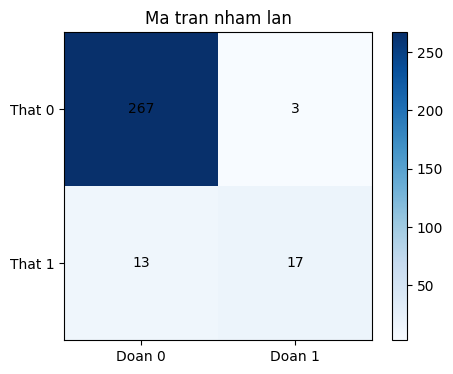

In [3]:
pred_lr=logreg.predict(Xte)
ytrue=np.asarray(yte); yp=np.asarray(pred_lr)
TN=int(((ytrue==0)&(yp==0)).sum());FP=int(((ytrue==0)&(yp==1)).sum())
FN=int(((ytrue==1)&(yp==0)).sum());TP=int(((ytrue==1)&(yp==1)).sum())
print('TN, FP, FN, TP:',TN,FP,FN,TP)
cm=confusion_matrix(yte,pred_lr)
print('Confusion matrix (hang that, cot du doan):');display(pd.DataFrame(cm,index=['That 0','That 1'],columns=['Doan 0','Doan 1']))
assert np.array_equal(cm,np.array([[TN,FP],[FN,TP]]))
plt.figure(figsize=(5,4));plt.imshow(cm,cmap='Blues');plt.xticks([0,1],['Doan 0','Doan 1']);plt.yticks([0,1],['That 0','That 1'])
for (i,j),v in np.ndenumerate(cm):plt.text(j,i,v,ha='center',va='center')
plt.title('Ma tran nham lan');plt.colorbar();plt.savefig('ket_qua/lab07_buoc2_confusion.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 3 (mục 4): Precision, Recall và F1-score

In [4]:
precision_manual=TP/(TP+FP) if TP+FP else 0
recall_manual=TP/(TP+FN) if TP+FN else 0
f1_manual=2*precision_manual*recall_manual/(precision_manual+recall_manual) if precision_manual+recall_manual else 0
print('Tu tinh: precision=',round(precision_manual,4),'recall=',round(recall_manual,4),'F1=',round(f1_manual,4))
print('Sklearn:',precision_score(yte,pred_lr),recall_score(yte,pred_lr),f1_score(yte,pred_lr))
print('Classification report:',classification_report(yte,pred_lr,zero_division=0))

Tu tinh: precision= 0.85 recall= 0.5667 F1= 0.68
Sklearn: 0.85 0.5666666666666667 0.68
Classification report:               precision    recall  f1-score   support

           0       0.95      0.99      0.97       270
           1       0.85      0.57      0.68        30

    accuracy                           0.95       300
   macro avg       0.90      0.78      0.83       300
weighted avg       0.94      0.95      0.94       300



### Bước 4 (mục 5): Đổi ngưỡng và chọn ngưỡng bằng CV trên tập học

In [5]:
proba_test=logreg.predict_proba(Xte)[:,1]
rows=[]
for t in [.5,.4,.3,.2,.1]:
    pp=(proba_test>=t).astype(int)
    rows.append([t,int(pp.sum()),precision_score(yte,pp,zero_division=0),recall_score(yte,pp),f1_score(yte,pp)])
display(pd.DataFrame(rows,columns=['Nguong','So nguoi bao','Precision','Recall','F1']).round(4))
base_lr=make_pipeline(StandardScaler(),LogisticRegression())
cv_proba=cross_val_predict(base_lr,Xtr,ytr,cv=5,method='predict_proba')[:,1]
thresholds=np.round(np.arange(.05,.96,.05),2)
f1cv=np.array([f1_score(ytr,(cv_proba>=t).astype(int),zero_division=0) for t in thresholds])
t_f1=float(thresholds[f1cv.argmax()]); p_f1=(proba_test>=t_f1).astype(int)
print('Nguong cho F1 CV cao nhat:',t_f1,'| F1 CV:',round(f1cv.max(),4))
print('Danh gia tren TEST duy nhat:',{'Precision':precision_score(yte,p_f1),'Recall':recall_score(yte,p_f1),'F1':f1_score(yte,p_f1)})

,Nguong,So nguoi bao,Precision,Recall,F1
0,0.5,20,0.8500,0.5667,0.6800
1,0.4,21,0.8571,0.6000,0.7059
2,0.3,29,0.7241,0.7000,0.7119
3,0.2,42,0.5714,0.8000,0.6667
4,0.1,61,0.4262,0.8667,0.5714


Nguong cho F1 CV cao nhat: 0.25 | F1 CV: 0.6473
Danh gia tren TEST duy nhat: {'Precision': 0.6571428571428571, 'Recall': 0.7666666666666667, 'F1': 0.7076923076923077}


### Bước 5 (mục 6): ROC, AUC và so sánh các mô hình

Logistic             AUC=0.9449, recall=0.5667, F1=0.6800
Naive Bayes          AUC=0.9336, recall=0.3667, F1=0.5116
KNN 15               AUC=0.9274, recall=0.2333, F1=0.3684
Decision Tree 4      AUC=0.8803, recall=0.4667, F1=0.5957
Random Forest 200    AUC=0.9249, recall=0.5667, F1=0.6538
SVM RBF              AUC=0.8996, recall=0.5000, F1=0.6383


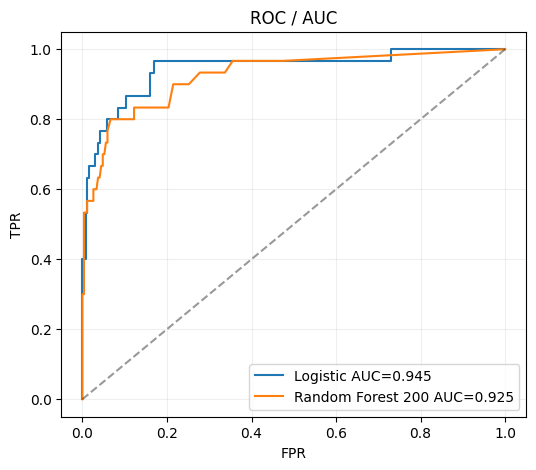

In [6]:
from sklearn.metrics import roc_curve,roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
models={'Logistic':make_pipeline(StandardScaler(),LogisticRegression()),'Naive Bayes':GaussianNB(),'KNN 15':make_pipeline(StandardScaler(),KNeighborsClassifier(15)),'Decision Tree 4':DecisionTreeClassifier(max_depth=4,random_state=0),'Random Forest 200':RandomForestClassifier(200,random_state=0),'SVM RBF':make_pipeline(StandardScaler(),SVC(probability=True,random_state=0))}
roc_data={}
for name,m in models.items():
    m.fit(Xtr,ytr); probs=m.predict_proba(Xte)[:,1]
    fpr,tpr,_=roc_curve(yte,probs)
    roc_data[name]=(fpr,tpr,roc_auc_score(yte,probs))
    print(f'{name:20s} AUC={roc_data[name][2]:.4f}, recall={recall_score(yte,m.predict(Xte)):.4f}, F1={f1_score(yte,m.predict(Xte)):.4f}')
plt.figure(figsize=(6,5))
for name in ['Logistic','Random Forest 200']:
    fpr,tpr,auc=roc_data[name];plt.plot(fpr,tpr,label=f'{name} AUC={auc:.3f}')
plt.plot([0,1],[0,1],'k--',alpha=.4);plt.xlabel('FPR');plt.ylabel('TPR');plt.title('ROC / AUC');plt.legend();plt.grid(alpha=.2)
plt.savefig('ket_qua/lab07_buoc5_roc.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 6 (mục 7): Phân tầng, cross-validation và class_weight

In [7]:
without_strat=[]
for rs in range(10):
    _,_,_,ytmp=train_test_split(students.drop(columns='bo_hoc'),students.bo_hoc,test_size=.25,random_state=rs)
    without_strat.append(int(ytmp.sum()))
print('So hoc sinh bo hoc trong test neu khong stratify:',without_strat)
for metric in ['accuracy','precision','recall','f1']:
    scores=cross_val_score(base_lr,Xtr,ytr,cv=5,scoring=metric)
    print(metric,':',round(scores.mean(),4))
for name,m in [('Thuong',base_lr),('Balanced',make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced')))]:
    p=m.fit(Xtr,ytr).predict(Xte)
    print(name,': precision',round(precision_score(yte,p),4),'recall',round(recall_score(yte,p),4),'F1',round(f1_score(yte,p),4))

So hoc sinh bo hoc trong test neu khong stratify: [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]
accuracy : 0.9289
precision : 0.7044
recall : 0.481
f1 : 0.5652
Thuong : precision 0.85 recall 0.5667 F1 0.68
Balanced : precision 0.4483 recall 0.8667 F1 0.5909


## Phần II — Giải 6 bài tập Lab 07

### Bài tập 1 — Viết hàm đánh giá chỉ dùng numpy

In [8]:
def danh_gia(y_that,y_doan):
    y0=np.asarray(y_that);p=np.asarray(y_doan)
    tp=np.sum((y0==1)&(p==1));fp=np.sum((y0==0)&(p==1));fn=np.sum((y0==1)&(p==0))
    acc=np.mean(y0==p);pre=tp/(tp+fp) if tp+fp else 0.0
    rec=tp/(tp+fn) if tp+fn else 0.0
    f1=2*pre*rec/(pre+rec) if pre+rec else 0.0
    return acc,pre,rec,f1
for name,m in [('Logistic',logreg),('Dummy',dummy)]:
    p=m.predict(Xte)
    print(name,': numpy:',np.round(danh_gia(yte,p),4),'| sklearn:',[round(fn(yte,p,zero_division=0),4) if fn!=accuracy_score else round(fn(yte,p),4) for fn in (accuracy_score,precision_score,recall_score,f1_score)])
print('Giai thich: dummy khong du doan lop 1 -> TP+FP=0, precision khong xac dinh theo toan hoc; o day quy uoc bang 0 de tranh chia 0.')

Logistic : numpy: [0.9467 0.85   0.5667 0.68  ] | sklearn: [0.9467, 0.85, 0.5667, 0.68]
Dummy : numpy: [0.9 0.  0.  0. ] | sklearn: [0.9, 0.0, 0.0, 0.0]
Giai thich: dummy khong du doan lop 1 -> TP+FP=0, precision khong xac dinh theo toan hoc; o day quy uoc bang 0 de tranh chia 0.


### Bài tập 2 — Classification report cho 10 chữ số

In [9]:
from sklearn.datasets import load_digits
Xd,yd=load_digits(return_X_y=True)
Xdtr,Xdte,ydtr,ydte=train_test_split(Xd,yd,test_size=.25,random_state=17,stratify=yd)
svm_digit=SVC().fit(Xdtr,ydtr);pdigit=svm_digit.predict(Xdte)
print(classification_report(ydte,pdigit,zero_division=0))
from sklearn.metrics import precision_recall_fscore_support
pr,re,_,_=precision_recall_fscore_support(ydte,pdigit,labels=np.arange(10),zero_division=0)
print('Recall thap nhat:',np.where(re==min(re))[0].tolist(),'| Precision thap nhat:',np.where(pr==min(pr))[0].tolist())
print('Nhan xet: so mau tung chu so gan nhau nen weighted avg va macro avg thuong rat gan nhau.')

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.98      1.00      0.99        46
           2       1.00      1.00      1.00        44
           3       0.98      1.00      0.99        46
           4       1.00      0.98      0.99        45
           5       1.00      1.00      1.00        46
           6       1.00      1.00      1.00        45
           7       1.00      0.98      0.99        45
           8       0.98      0.98      0.98        43
           9       0.98      0.98      0.98        45

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450

Recall thap nhat: [8] | Precision thap nhat: [8]
Nhan xet: so mau tung chu so gan nhau nen weighted avg va macro avg thuong rat gan nhau.


### Bài tập 3 — Chọn ngưỡng lớn nhất để recall CV ≥ 0.80

In [10]:
# Chon nguong duoc bang ket qua OOF tren TAP HOC, khong nhin tap test.
valid_thresholds=np.unique(np.r_[0.0,cv_proba,1.0])
rec_train=np.array([recall_score(ytr,(cv_proba>=t).astype(int)) for t in valid_thresholds])
select=valid_thresholds[rec_train>=.8]
assert len(select)>0
t_80=float(select.max())
pred_80=(proba_test>=t_80).astype(int)
print('Nguong lon nhat dat >=80% recall OOF:',round(t_80,6))
print('Recall CV:',rec_train[np.where(valid_thresholds==t_80)[0][0]])
print('TEST: recall=',round(recall_score(yte,pred_80),4),'precision=',round(precision_score(yte,pred_80),4),'so ban duoc bao=',int(pred_80.sum()))
print('Nhan xet: Recall tren test khong duoc bao dam >=0.8 do sai khac lay mau; dung CV de chon truoc.')

Nguong lon nhat dat >=80% recall OOF: 0.171774
Recall CV: 0.8089887640449438
TEST: recall= 0.8 precision= 0.5106 so ban duoc bao= 47
Nhan xet: Recall tren test khong duoc bao dam >=0.8 do sai khac lay mau; dung CV de chon truoc.


### Bài tập 4 — Tự vẽ ROC hai mô hình và lưu roc.png

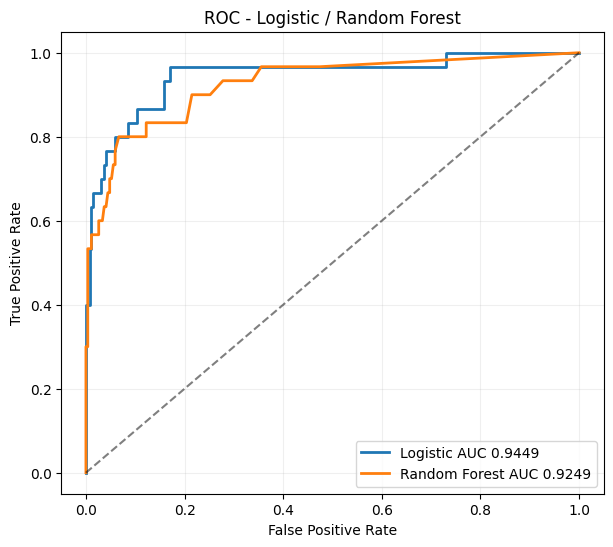

AUC lon hon: Logistic | Hai duong co doan cat/doi thu tu: True
Nhan xet: duong co AUC lon thuong nam gan goc tren ben trai hon tren nhieu nguong; duong ROC van co the giao nhau.


In [11]:
fl,tl,al=roc_data['Logistic'];fr,tr,ar=roc_data['Random Forest 200']
plt.figure(figsize=(7,6));plt.plot(fl,tl,label=f'Logistic AUC {al:.4f}',lw=2);plt.plot(fr,tr,label=f'Random Forest AUC {ar:.4f}',lw=2)
plt.plot([0,1],[0,1],'k--',alpha=.5);plt.xlabel('False Positive Rate');plt.ylabel('True Positive Rate');plt.title('ROC - Logistic / Random Forest');plt.legend();plt.grid(alpha=.2)
plt.savefig('ket_qua/roc.png',dpi=160,bbox_inches='tight');plt.show()
gridf=np.linspace(0,1,1001);diff=np.interp(gridf,fl,tl)-np.interp(gridf,fr,tr)
cross=np.any((diff[:-1]*diff[1:]<0))
print('AUC lon hon:', 'Logistic' if al>ar else 'Random Forest','| Hai duong co doan cat/doi thu tu:',bool(cross))
print('Nhan xet: duong co AUC lon thuong nam gan goc tren ben trai hon tren nhieu nguong; duong ROC van co the giao nhau.')

### Bài tập 5 — Class weight balanced cho Random Forest và SVC

In [12]:
results=[]
for family in ['Random Forest','SVC']:
    for balanced in [False,True]:
        weight='balanced' if balanced else None
        m=RandomForestClassifier(n_estimators=200,random_state=0,class_weight=weight) if family=='Random Forest' else make_pipeline(StandardScaler(),SVC(class_weight=weight,random_state=0))
        p=m.fit(Xtr,ytr).predict(Xte)
        results.append([family,'Balanced' if balanced else 'Default',precision_score(yte,p,zero_division=0),recall_score(yte,p),f1_score(yte,p)])
res=pd.DataFrame(results,columns=['Model','Weight','Precision','Recall','F1']);display(res.round(4))
for name,g in res.groupby('Model'):
    print(name,'| chenh lech F1:',round(abs(g.iloc[1]['F1']-g.iloc[0]['F1']),4))
print('Nhan xet: so sanh theo chenh lech quan sat duoc, balanced khong phai luc nao cung lam F1 tang.')

,Model,Weight,Precision,Recall,F1
0,Random Forest,Default,0.7727,0.5667,0.6538
1,Random Forest,Balanced,0.7500,0.4000,0.5217
2,SVC,Default,0.8824,0.5000,0.6383
3,SVC,Balanced,0.4464,0.8333,0.5814


Random Forest | chenh lech F1: 0.1321
SVC | chenh lech F1: 0.0569
Nhan xet: so sanh theo chenh lech quan sat duoc, balanced khong phai luc nao cung lam F1 tang.


### Bài tập 6 — MAE, RMSE và R² sau một dự đoán sai 5 tỷ

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
house=pd.read_csv('data/gia_nha.csv')
Xhtr,Xhte,yhtr,yhte=train_test_split(house.drop(columns='gia'),house['gia'],test_size=.25,random_state=17)
lr_house=LinearRegression().fit(Xhtr,yhtr)
yhat=lr_house.predict(Xhte)
def regression_scores(truth,pred):
    return {'MAE':mean_absolute_error(truth,pred),'RMSE':np.sqrt(mean_squared_error(truth,pred)),'R2':r2_score(truth,pred)}
ybad=yhat.copy();ybad[0]+=5.0
before=regression_scores(yhte,yhat);after=regression_scores(yhte,ybad)
display(pd.DataFrame({'Binh thuong':before,'1 du doan +5 ty':after,'Chenh lech':{k:after[k]-before[k] for k in before}}).round(4))
print('Giai thich: RMSE binh phuong sai so truoc khi lay trung binh, nen mot sai so lon anh huong rat manh. R2 cung giam khi tong sai so binh phuong tang.')

,Binh thuong,1 du doan +5 ty,Chenh lech
MAE,0.2185,0.5519,0.3333
RMSE,0.2700,1.4433,1.1733
R2,0.9759,0.3110,-0.6649


Giai thich: RMSE binh phuong sai so truoc khi lay trung binh, nen mot sai so lon anh huong rat manh. R2 cung giam khi tong sai so binh phuong tang.
